# Basic strategies — volatility and positive momentum

We now use the Part 0 foundation to compare a few explicit rules. No ML or
factor selection is involved. First read [01_strategy_rules.md](01_strategy_rules.md)
for the fixed lookback, baskets, fallbacks, and calendar convention.

The three ideas are high volatility, low volatility, and positive momentum with
more capital assigned to stronger momentum. Two equal-weight controls and an
equal-weight momentum basket help identify what each change does.

All stocks and dates come from the supplied class files. Earlier test results
have already been viewed in this project. The 2010–2018 table is a historical
comparison of these fixed rules, not a newly untouched model-selection sample.

In [1]:
from pathlib import Path
import sys
import json
import hashlib
import platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display, Markdown

# Work from this folder, the project folder, or the course folder.
HERE = next(
    candidate
    for base in [Path.cwd(), *Path.cwd().parents]
    for candidate in [base, base / '0_1_Basic_Strategies',
                      base / '11_mlfactor_long_only_project_2026' / '0_1_Basic_Strategies']
    if (candidate / 'strategies.py').is_file()
)
if str(HERE) not in sys.path:
    sys.path.insert(0, str(HERE))
from strategies import (
    LABELS, LOOKBACK_MONTHS, BASKET_FRACTION, build_signals, run_comparison,
    load_panel, portfolio_returns, performance,
)
ROOT = HERE.parent
OUT = HERE / 'outputs'
FIGURES = OUT / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_columns', 12)
pd.set_option('display.max_rows', 25)
COLORS = dict(zip(LABELS, ['#333333', '#999999', '#c26939', '#257b75', '#477fa8', '#8f5688']))

def save_figure(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / (name + '.png'), dpi=160, bbox_inches='tight')
    fig.savefig(FIGURES / (name + '.svg'), bbox_inches='tight')
    plt.show()

# Write the specification before any backtest numbers are calculated here.
config = {
    'lookback_months': LOOKBACK_MONTHS,
    'basket_fraction': BASKET_FRACTION,
    'momentum': 'Last 12 realized monthly gross returns multiplied, minus one; no skipped recent month',
    'volatility': 'Sample standard deviation of last 12 realized monthly simple returns times sqrt(12)',
    'momentum_weights': 'Positive trailing-momentum scores normalized within the selected basket, uncapped',
    'fallbacks': 'No positive momentum: eligible equal weight; no eligible history: universe equal weight',
    'rebalance': 'Monthly at the snapshot, earning the existing forward next-month label',
    'risk_free_monthly': 0.0, 'costs': 'None deducted',
    'ties': 'Lower security ID first',
    'strategies': LABELS,
    'rules_sha256': hashlib.sha256((HERE / '01_strategy_rules.md').read_bytes()).hexdigest(),
}
(OUT / 'strategy_specification.json').write_text(json.dumps(config, indent=2) + '\n')
display(pd.Series({key: config[key] for key in ['lookback_months', 'basket_fraction', 'rebalance', 'risk_free_monthly', 'costs']}))

lookback_months                                                     12
basket_fraction                                                    0.2
rebalance            Monthly at the snapshot, earning the existing ...
risk_free_monthly                                                  0.0
costs                                                    None deducted
dtype: object

## 1. Understand the lag before reading the result

A December 2009 snapshot earns January 2010. Its volatility and momentum signals
must instead use returns already realized by December 2009. Those returns are
stored on January–December 2009's **preceding snapshots**.

The signals are reconstructed on an earned-month calendar. At each decision,
only current stocks with twelve consecutive known returns are eligible. The
first twelve training return months provide history for all later comparisons.
The first test rebalance uses earlier training history; subsequent test
rebalances can use earlier test returns after those months have actually ended.
Rules and parameters remain fixed.

In [2]:
result = run_comparison(ROOT)
metrics = result['metrics']
books = result['books']
signals = result['signals']
audit = result['diagnostics']

# Independently check the first test signal for one currently eligible stock.
boundary = pd.Timestamp('2009-12-31')
row = signals.loc[signals.date.eq(boundary) & signals.eligible].iloc[0]
train = load_panel('train', ROOT)
history = train.loc[
    train.stock_id.eq(row.stock_id)
    & train.date.between('2008-12-31', '2009-11-30'),
    'R1M_Usd',
]
assert len(history) == 12
assert np.isclose(row.trailing_momentum, np.prod(1 + history) - 1)
assert np.isclose(row.trailing_volatility, history.std(ddof=1) * np.sqrt(12))
print(f'First test signal checked independently for stock {int(row.stock_id)}:')
print('Decision: December 2009; known returns: January–December 2009; next earned return: January 2010.')
windows = metrics.groupby('split')[['first_return_month', 'last_return_month', 'months']].first()
display(windows)
assert metrics['months'].eq(108).all()
assert windows.loc['train', 'first_return_month'] == pd.Timestamp('2001-01-31')
assert windows.loc['test', 'first_return_month'] == pd.Timestamp('2010-01-31')

First test signal checked independently for stock 1:
Decision: December 2009; known returns: January–December 2009; next earned return: January 2010.


,first_return_month,last_return_month,months
split,,,
test,2010-01-31,2018-12-31,108.0
train,2001-01-31,2009-12-31,108.0


## 2. What are we comparing?

The universe control holds every available stock equally. The eligible control
holds only stocks with the required history. Their difference isolates the
history requirement.

High- and low-volatility baskets take opposite ends of the volatility ranking,
with equal capital in about 20% of eligible stocks. Momentum takes up to the same
number of positive trailing-return names. Its equal-weight and score-weight
versions use identical selections. The score-weight version tilts capital more
strongly toward the winners. It does not borrow, short, or forecast a trend.

If there are no positive momentum names, the momentum books hold eligible stocks
equally. This is an invested fallback, not a switch to cash. The rules in this
experiment include the most recent realized month; they do not reproduce the
[French prior-months 2–12 momentum factor](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/Data_Library/det_mom_factor.html).

In [3]:
# Compare risk and reward on the exact same earned-return months.
metric_columns = ['cagr', 'annualized_volatility', 'sharpe', 'max_drawdown', 'avg_one_way_turnover', 'avg_names']
for split in ['train', 'test']:
    table = metrics.loc[metrics.split.eq(split)].set_index('strategy').loc[list(LABELS), metric_columns]
    table.index = table.index.map(LABELS)
    pretty = table.copy().astype(object)
    for col in ['cagr', 'annualized_volatility', 'max_drawdown', 'avg_one_way_turnover']:
        pretty[col] = table[col].map(lambda x: f'{x:.2%}')
    pretty['sharpe'] = table.sharpe.map(lambda x: f'{x:.3f}')
    pretty['avg_names'] = table.avg_names.map(lambda x: f'{x:.1f}')
    display(Markdown(f'**{split.capitalize()} period, matched months.**'))
    display(pretty)

# Keep the original complete equal-weight windows available, separately labeled.
full_benchmark = pd.DataFrame({
    split: performance(portfolio_returns(load_panel(split, ROOT)).simple_return)
    for split in ['train', 'test']
}).T
full_benchmark.index.name = 'split'
full_benchmark.to_csv(OUT / 'full_window_equal_weight_reference.csv')
original_test = portfolio_returns(load_panel('test', ROOT)).simple_return
np.testing.assert_allclose(books['test']['equal_weight_universe'].simple_return, original_test, atol=1e-14)
print('Test universe benchmark matches Part 0. Training comparison excludes warm-up; full reference is saved separately.')

**Train period, matched months.**

,cagr,annualized_volatility,sharpe,max_drawdown,avg_one_way_turnover,avg_names
strategy,,,,,,
Equal-weight universe,13.93%,20.61%,0.739,-49.51%,3.90%,1182.6
Equal-weight eligible stocks,13.70%,20.54%,0.731,-49.51%,3.91%,1167.3
"High volatility, equal weight",28.97%,34.61%,0.906,-57.95%,14.79%,233.8
"Low volatility, equal weight",6.97%,12.26%,0.614,-40.07%,13.11%,233.8
"Positive momentum, equal weight",6.81%,18.51%,0.450,-48.88%,26.53%,226.9
"Positive momentum, score weights",10.91%,21.19%,0.597,-53.45%,24.58%,226.9


**Test period, matched months.**

,cagr,annualized_volatility,sharpe,max_drawdown,avg_one_way_turnover,avg_names
strategy,,,,,,
Equal-weight universe,13.10%,15.63%,0.868,-20.64%,2.89%,1182.8
Equal-weight eligible stocks,13.10%,15.63%,0.868,-20.66%,2.88%,1181.7
"High volatility, equal weight",18.88%,23.44%,0.857,-29.21%,13.68%,236.8
"Low volatility, equal weight",10.23%,10.86%,0.955,-11.51%,14.21%,236.8
"Positive momentum, equal weight",11.08%,17.17%,0.699,-23.59%,25.06%,236.8
"Positive momentum, score weights",8.71%,19.67%,0.523,-28.81%,23.08%,236.8


Test universe benchmark matches Part 0. Training comparison excludes warm-up; full reference is saved separately.


## 3. Follow wealth and drawdown through time

Each split starts with one dollar. The wealth axes use a logarithmic scale so
proportional changes remain comparable. A high final value can coexist with an
uncomfortable drawdown; inspect both panels. Volatility-ranked individual stocks
need not produce a portfolio ranking in the same order, because their returns
can move together differently.

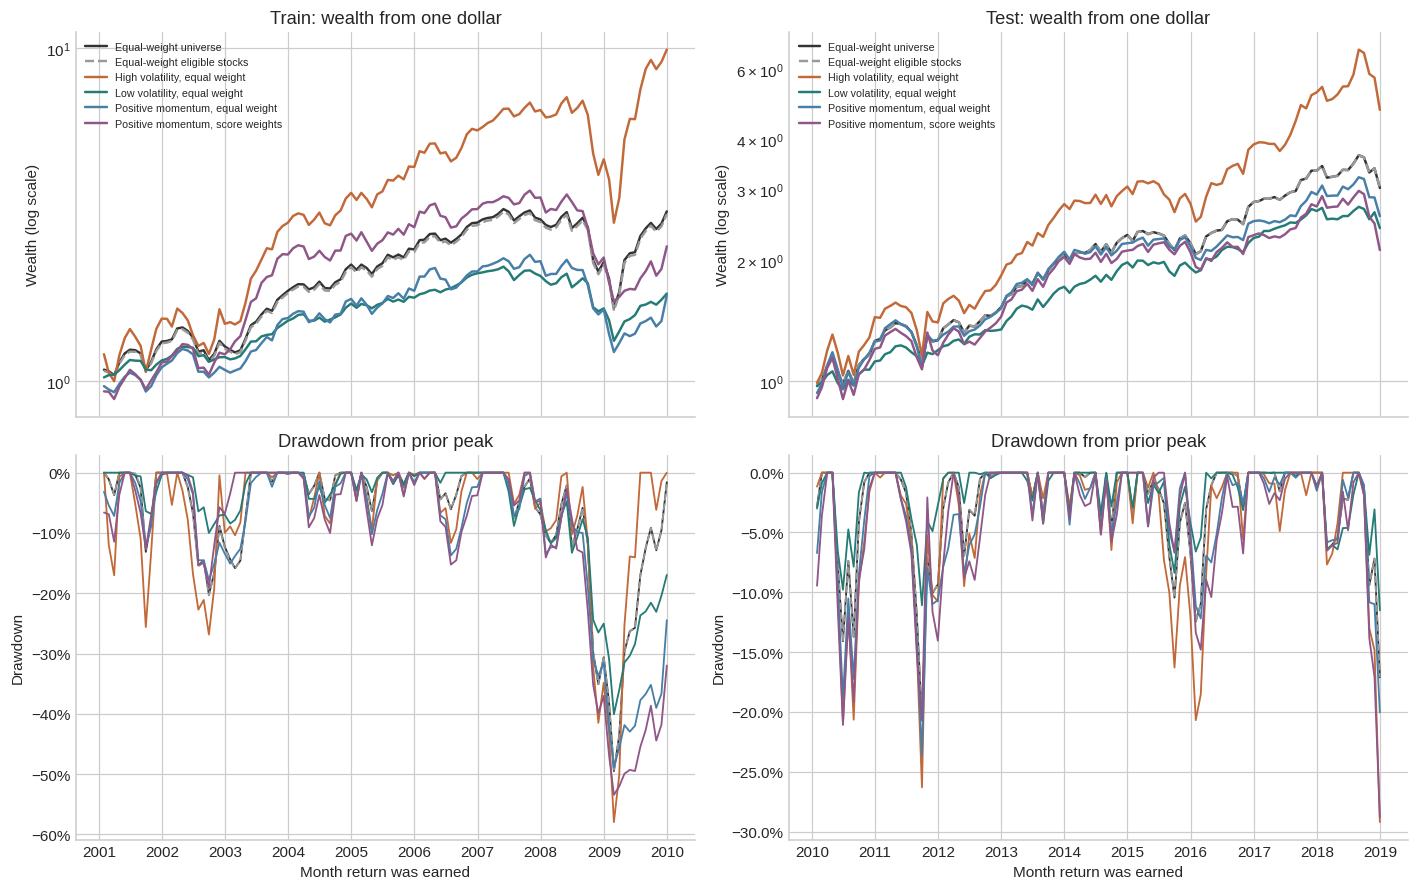

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8.2), sharex='col')
for col, split in enumerate(['train', 'test']):
    for strategy, label in LABELS.items():
        book = books[split][strategy]
        style = '--' if strategy == 'equal_weight_eligible' else '-'
        axes[0, col].plot(book.index, book.wealth, label=label, color=COLORS[strategy], linestyle=style, lw=1.6)
        axes[1, col].plot(book.index, book.drawdown, color=COLORS[strategy], linestyle=style, lw=1.2)
    axes[0, col].set_yscale('log')
    axes[0, col].set(title=f'{split.capitalize()}: wealth from one dollar', ylabel='Wealth (log scale)')
    axes[1, col].set(title='Drawdown from prior peak', ylabel='Drawdown', xlabel='Month return was earned')
    axes[1, col].yaxis.set_major_formatter(PercentFormatter(1))
    axes[0, col].legend(fontsize=7, loc='upper left')
save_figure(fig, '01_strategy_wealth_and_drawdown')

## 4. How did the rules do relative to the same universe?

Relative wealth is strategy wealth divided by universe wealth. A rising line
means the strategy is gaining relative to equal weight, even if both books are
losing money. A value above one means cumulative outperformance over that split.
This is different from a monthly return difference or the difference in CAGR.

Calendar-year tables help identify whether a result relies on a small part of
the sample. Both comparison periods contain complete years after the warm-up.

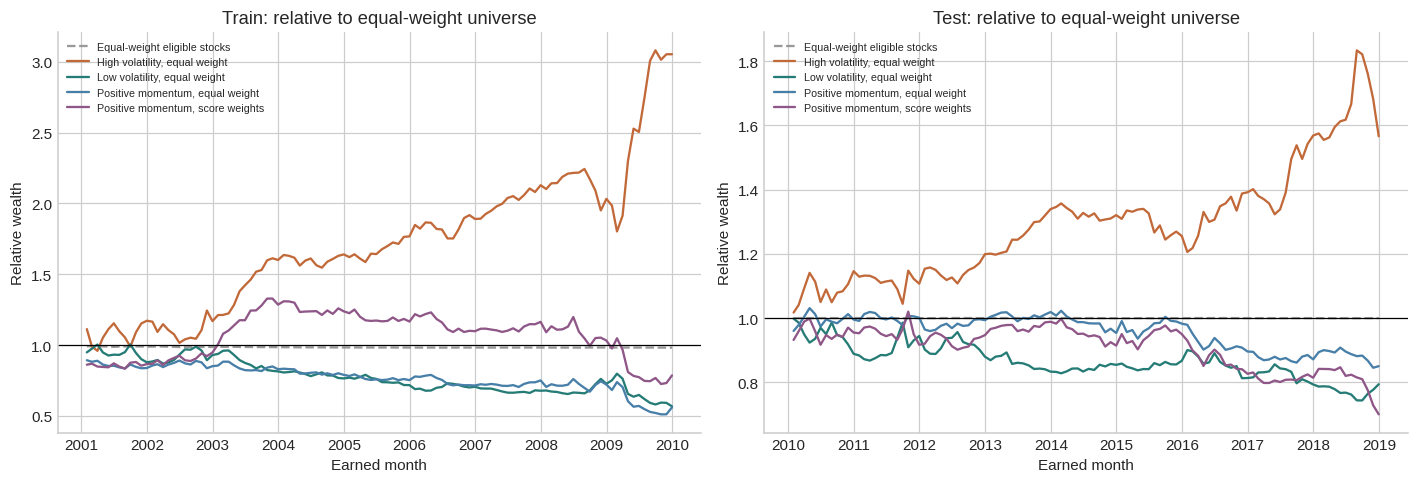

**Train: compounded calendar-year returns.**

strategy,Equal-weight universe,Equal-weight eligible stocks,"High volatility, equal weight","Low volatility, equal weight","Positive momentum, equal weight","Positive momentum, score weights"
year,,,,,,
2001,31.7%,30.1%,54.3%,15.6%,10.3%,13.9%
2002,-3.3%,-3.5%,-3.5%,2.4%,-1.8%,5.8%
2003,46.8%,46.5%,101.0%,28.5%,43.0%,99.1%
2004,19.9%,19.7%,22.8%,12.6%,14.1%,15.5%
2005,11.0%,10.9%,19.6%,4.1%,5.8%,4.6%
2006,20.3%,20.3%,28.7%,18.4%,14.3%,13.3%
2007,2.2%,2.2%,15.1%,-1.9%,7.3%,8.4%
2008,-25.5%,-25.4%,-28.8%,-20.1%,-28.4%,-33.9%
2009,41.8%,41.7%,113.1%,10.8%,10.2%,8.0%


**Test: compounded calendar-year returns.**

strategy,Equal-weight universe,Equal-weight eligible stocks,"High volatility, equal weight","Low volatility, equal weight","Positive momentum, equal weight","Positive momentum, score weights"
year,,,,,,
2010,25.8%,25.8%,44.2%,11.8%,25.2%,20.1%
2011,0.4%,0.4%,-3.0%,6.7%,1.0%,-3.6%
2012,20.9%,20.9%,30.9%,12.6%,19.9%,24.8%
2013,34.9%,34.9%,50.7%,27.8%,38.4%,40.8%
2014,12.2%,12.2%,10.6%,15.1%,5.0%,3.8%
2015,-4.6%,-4.6%,-9.3%,-3.2%,-1.7%,-0.9%
2016,26.7%,26.7%,40.4%,18.8%,15.5%,10.2%
2017,19.7%,19.7%,34.9%,16.8%,16.4%,17.9%
2018,-9.5%,-9.4%,-9.6%,-9.4%,-11.6%,-22.1%


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, split in zip(axes, ['train', 'test']):
    for strategy, label in LABELS.items():
        if strategy == 'equal_weight_universe':
            continue
        rows = result['active'].loc[result['active'].split.eq(split) & result['active'].strategy.eq(strategy)]
        ax.plot(rows.return_month, rows.relative_wealth, label=label, color=COLORS[strategy],
                linestyle='--' if strategy == 'equal_weight_eligible' else '-')
    ax.axhline(1, color='black', lw=0.8)
    ax.set(title=f'{split.capitalize()}: relative to equal-weight universe', ylabel='Relative wealth', xlabel='Earned month')
    ax.legend(fontsize=7)
save_figure(fig, '02_relative_wealth')

yearly_rows = []
for split in ['train', 'test']:
    for strategy, book in books[split].items():
        yearly = (1 + book.simple_return).groupby(book.index.year).prod() - 1
        yearly_rows.extend({'split': split, 'strategy': strategy, 'year': year, 'simple_return': value}
                           for year, value in yearly.items())
yearly = pd.DataFrame(yearly_rows)
yearly.to_csv(OUT / 'calendar_year_returns.csv', index=False)
for split in ['train', 'test']:
    table = yearly.loc[yearly.split.eq(split)].pivot(index='year', columns='strategy', values='simple_return').reindex(columns=list(LABELS))
    table.columns = table.columns.map(LABELS)
    display(Markdown(f'**{split.capitalize()}: compounded calendar-year returns.**'))
    display(table.map(lambda x: f'{x:.1%}'))

## 5. More weight on momentum can mean fewer effective holdings

Holding 230 names does not imply that capital is diversified across 230 names.
The effective number of holdings is `1 / sum(weight**2)`: equal weights give the
actual count, while concentration reduces it. The momentum-weighted book has no
single-name cap, making the effect visible rather than hiding it.

Turnover includes drift in old weights after their returns. Initial funding is
excluded, and no transaction-cost deduction is silently added. Gross returns,
turnover, maximum weight, and concentration should be considered together.

**Train: allocation diagnostics.**

,avg_names,avg_effective_n,largest_single_weight,avg_one_way_turnover,fallback_months
strategy,,,,,
Equal-weight universe,1182.6204,1182.6204,0.0009,0.0390,0
Equal-weight eligible stocks,1167.2778,1167.2778,0.0010,0.0391,0
"High volatility, equal weight",233.8241,233.8241,0.0048,0.1479,0
"Low volatility, equal weight",233.8241,233.8241,0.0048,0.1311,0
"Positive momentum, equal weight",226.9352,226.9352,0.0120,0.2653,0
"Positive momentum, score weights",226.9352,114.4265,0.3202,0.2458,0


**Test: allocation diagnostics.**

,avg_names,avg_effective_n,largest_single_weight,avg_one_way_turnover,fallback_months
strategy,,,,,
Equal-weight universe,1182.7778,1182.7778,0.0009,0.0289,0
Equal-weight eligible stocks,1181.6667,1181.6667,0.0009,0.0288,0
"High volatility, equal weight",236.8241,236.8241,0.0045,0.1368,0
"Low volatility, equal weight",236.8241,236.8241,0.0045,0.1421,0
"Positive momentum, equal weight",236.8241,236.8241,0.0045,0.2506,0
"Positive momentum, score weights",236.8241,113.0787,0.1653,0.2308,0


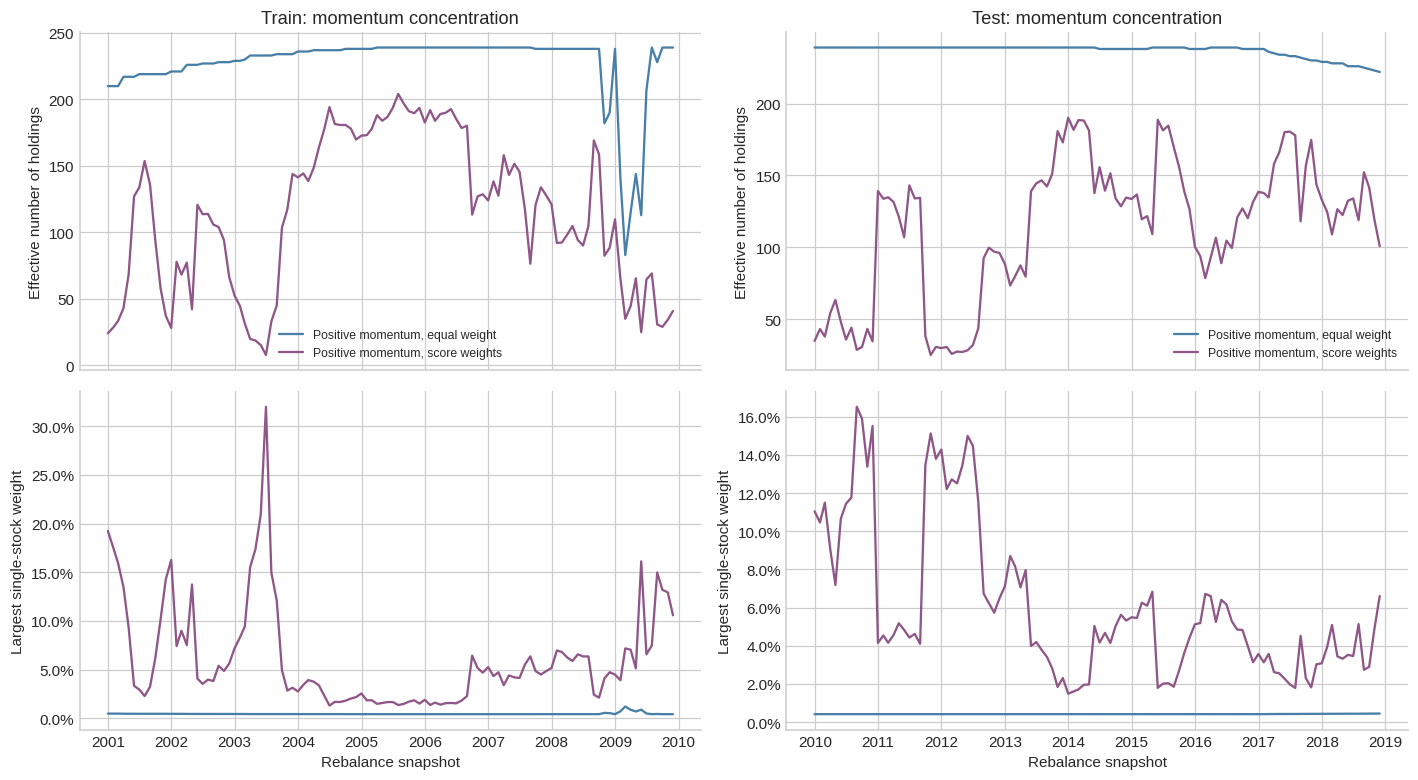

In [6]:
diag_columns = ['avg_names', 'avg_effective_n', 'largest_single_weight', 'avg_one_way_turnover', 'fallback_months']
for split in ['train', 'test']:
    table = metrics.loc[metrics.split.eq(split)].set_index('strategy').loc[list(LABELS), diag_columns]
    table.index = table.index.map(LABELS)
    display(Markdown(f'**{split.capitalize()}: allocation diagnostics.**'))
    display(table.round(4))
fig, axes = plt.subplots(2, 2, figsize=(13, 7.2), sharex='col')
for col, split in enumerate(['train', 'test']):
    dates = books[split]['equal_weight_universe'].snapshot_date
    for strategy in ['momentum_equal_weight', 'momentum_weighted']:
        rows = audit.loc[audit.strategy.eq(strategy) & audit.date.isin(dates)]
        axes[0, col].plot(rows.date, rows.effective_n, label=LABELS[strategy], color=COLORS[strategy])
        axes[1, col].plot(rows.date, rows.max_weight, label=LABELS[strategy], color=COLORS[strategy])
    axes[0, col].set(title=f'{split.capitalize()}: momentum concentration', ylabel='Effective number of holdings')
    axes[1, col].set(ylabel='Largest single-stock weight', xlabel='Rebalance snapshot')
    axes[1, col].yaxis.set_major_formatter(PercentFormatter(1))
    axes[0, col].legend(fontsize=8)
save_figure(fig, '03_momentum_concentration')

## 6. Inspect actual allocations and the largest return contributions

December 2009 is the first test decision. The table shows the ten highest
momentum scores selected at that snapshot and compares equal weights with score
weights. The forward return is absent from this decision table.

The contribution audit below is computed afterward. It identifies the largest
absolute `weight * realized_return` observations in each book. Those numbers
explain one month's portfolio return; they are not shares of annual compounded
performance. Large supplied returns remain in every calculation.

In [7]:
example = signals.loc[signals.date.eq(boundary)].merge(result['weights'], on=['date', 'stock_id'], validate='one_to_one')
example = example.loc[example.momentum_weighted.gt(0)].sort_values(['trailing_momentum', 'stock_id'], ascending=[False, True])
example_columns = ['date', 'stock_id', 'history_months', 'trailing_volatility', 'trailing_momentum', 'momentum_equal_weight', 'momentum_weighted']
example[example_columns].to_csv(OUT / 'first_test_momentum_allocation.csv', index=False)
display(example[example_columns].head(10).round(4))

# Independent stock-contribution sums must reproduce all portfolio monthly returns.
contributions = []
for split in ['train', 'test']:
    panel = load_panel(split, ROOT)
    joined = panel[['date', 'stock_id', 'R1M_Usd']].merge(result['weights'], on=['date', 'stock_id'], how='inner', validate='one_to_one')
    for strategy in LABELS:
        weighted = joined.R1M_Usd * joined[strategy]
        totals = weighted.groupby(joined.date).sum()
        expected = books[split][strategy].simple_return
        np.testing.assert_allclose(totals, expected, atol=1e-12)
        ids = weighted.abs().nlargest(5).index
        rows = joined.loc[ids, ['date', 'stock_id', 'R1M_Usd', strategy]].rename(columns={strategy: 'weight'})
        rows['return_contribution'] = weighted.loc[ids]
        rows['split'] = split
        rows['strategy'] = strategy
        rows['return_month'] = (rows.date.dt.to_period('M') + 1).dt.to_timestamp('M')
        contributions.append(rows)
contributions = pd.concat(contributions, ignore_index=True)
contributions.to_csv(OUT / 'largest_stock_return_contributions.csv', index=False)
display(contributions.loc[contributions.split.eq('test') & contributions.strategy.eq('high_volatility')].round(5))
print('Independent contribution sums reproduce every strategy return in both periods.')

,date,stock_id,history_months,trailing_volatility,trailing_momentum,momentum_equal_weight,momentum_weighted
219,2009-12-31,221,12,27.1781,45.9397,0.0042,0.1104
672,2009-12-31,683,12,9.8376,36.8109,0.0042,0.0885
107,2009-12-31,108,12,9.6491,19.8390,0.0042,0.0477
112,2009-12-31,113,12,2.2353,16.4579,0.0042,0.0396
849,2009-12-31,862,12,10.5013,15.4741,0.0042,0.0372
160,2009-12-31,162,12,3.0607,11.0277,0.0042,0.0265
780,2009-12-31,792,12,1.5602,8.8120,0.0042,0.0212
151,2009-12-31,153,12,1.6307,4.2282,0.0042,0.0102
668,2009-12-31,679,12,1.6106,3.5913,0.0042,0.0086
933,2009-12-31,949,12,1.2536,3.3153,0.0042,0.0080


,date,stock_id,R1M_Usd,weight,return_contribution,split,strategy,return_month
40,2018-07-31,885,30.176,0.00442,0.13352,test,high_volatility,2018-08-31
41,2017-07-31,663,24.430,0.00429,0.10485,test,high_volatility,2017-08-31
42,2011-09-30,317,16.913,0.00418,0.07077,test,high_volatility,2011-10-31
43,2017-06-30,213,12.198,0.00429,0.05235,test,high_volatility,2017-07-31
44,2018-06-30,775,11.105,0.00442,0.04914,test,high_volatility,2018-07-31


Independent contribution sums reproduce every strategy return in both periods.


## 7. Save the experiment and state what it establishes

The output files record the fixed specifications, monthly returns, diagnostics,
signals, and weights. A later feature-selection experiment can use these books
as reference strategies while retaining the same accounting and common months.
We have not searched these data for the best lookback or basket size.

In [8]:
metrics.to_csv(OUT / 'strategy_comparison.csv', index=False)
result['monthly'].to_csv(OUT / 'monthly_strategy_returns.csv', index=False)
result['active'].to_csv(OUT / 'monthly_active_returns.csv', index=False)
audit.to_csv(OUT / 'allocation_diagnostics.csv', index=False)
for name, frame in [('historical_signals', signals), ('portfolio_weights', result['weights'])]:
    frame.to_csv(OUT / (name + '.csv.gz'), index=False, compression={'method': 'gzip', 'mtime': 0})
manifest = {
    'source_files': {
        path.name: hashlib.sha256(path.read_bytes()).hexdigest()
        for path in [ROOT / 'mlfactor_long_only_train.csv', ROOT / 'mlfactor_long_only_test.csv',
                     ROOT / 'part0_data_and_benchmark' / 'pipeline.py', HERE / 'strategies.py', HERE / '01_strategy_rules.md']
    },
    'config': config,
    'libraries': {'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__, 'matplotlib': matplotlib.__version__},
    'windows': {split: {key: str(value) for key, value in row.items()} for split, row in windows.iterrows()},
    'test_status': 'Previously inspected historical period; not a new untouched holdout',
}
(OUT / 'run_manifest.json').write_text(json.dumps(manifest, indent=2) + '\n')

lines = ['# Findings from the executed basic-strategy comparison', '',
         'Source: `02_basic_strategy_comparison.ipynb`. Rules: twelve realized months, 20% baskets, monthly rebalancing, raw supplied returns, no ML or tuning.', '',
         'Training comparison: earned January 2001–December 2009 (after warm-up). Test comparison: January 2010–December 2018. Earlier test inspection is documented; this is not a fresh holdout.', '']
for split in ['train', 'test']:
    lines.extend([f'## {split.capitalize()}', '',
                  '| Strategy | CAGR | Volatility | Sharpe (rf=0) | Max drawdown | Turnover |',
                  '| --- | --- | --- | --- | --- | --- |'])
    for name in LABELS:
        row = metrics.loc[metrics.split.eq(split) & metrics.strategy.eq(name)].iloc[0]
        lines.append(f'| {LABELS[name]} | {row.cagr:.2%} | {row.annualized_volatility:.2%} | {row.sharpe:.3f} | {row.max_drawdown:.2%} | {row.avg_one_way_turnover:.2%} |')
    lines.append('')
for split in ['train', 'test']:
    by_name = metrics.loc[metrics.split.eq(split)].set_index('strategy')
    high, low = by_name.loc['high_volatility'], by_name.loc['low_volatility']
    ew_mom, weighted = by_name.loc['momentum_equal_weight'], by_name.loc['momentum_weighted']
    lines.extend([
        f'- {split.capitalize()}: high-volatility CAGR minus low-volatility CAGR is {high.cagr-low.cagr:+.2%}; volatility difference is {high.annualized_volatility-low.annualized_volatility:+.2%}.',
        f'- {split.capitalize()}: momentum score weights change CAGR by {weighted.cagr-ew_mom.cagr:+.2%} and Sharpe by {weighted.sharpe-ew_mom.sharpe:+.3f} relative to equal weights on the same names.',
        f'- {split.capitalize()}: momentum score weighting holds {weighted.avg_names:.1f} names on average but {weighted.avg_effective_n:.1f} effective holdings; its largest single weight is {weighted.largest_single_weight:.2%}.',
    ])
lines.extend(['', '## Interpretation and next experiment', '',
              'High return alone does not settle the comparison: assess volatility, drawdowns, turnover, concentration, and year-by-year behavior together. Positive historical momentum describes the past; it is not a guarantee of a continuing trend.', '',
              'The eligible equal-weight control separates the history requirement from selection. The two momentum books isolate the effect of allocation on a common selected basket. These are more informative comparisons than choosing a winner from final wealth alone.', '',
              'The next feature-selection experiment can compare a simple original-factor subset with all twenty features and these non-ML controls. Choose transformations, subsets, and model parameters using training-period chronological validation. Keep volatility and momentum separate from the original twenty-feature-subset requirement.', '',
              'No feature-selection list or Part 1 result was changed. No costs, cash timing, or weight caps were added in response to these results. Extreme supplied returns remain in the books; inspect `outputs/largest_stock_return_contributions.csv` before drawing conclusions about robustness.'])
(HERE / '03_findings.md').write_text('\n'.join(lines) + '\n')
display(Markdown('Saved the full comparison and [03_findings.md](03_findings.md).'))

Saved the full comparison and [03_findings.md](03_findings.md).